11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 784)
Testing data shape: (10000, 784)
Training labels shape: (60000, 10)
W1 shape: (784, 64)
b1 shape: (1, 64)
W2 shape: (64, 10)
b2 shape: (1, 10)
Epoch 1/10, Loss: 0.0451
Epoch 2/10, Loss: 0.0262
Epoch 3/10, Loss: 0.0219
Epoch 4/10, Loss: 0.0189
Epoch 5/10, Loss: 0.0176
Epoch 6/10, Loss: 0.0158
Epoch 7/10, Loss: 0.0145
Epoch 8/10, Loss: 0.0136
Epoch 9/10, Loss: 0.0128
Epoch 10/10, Loss: 0.0121


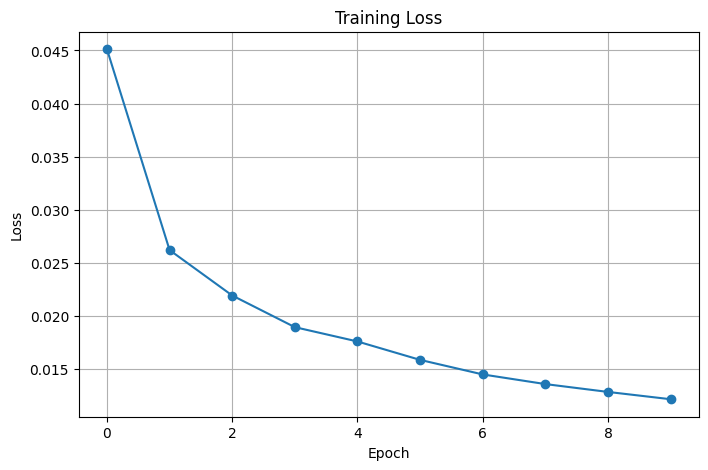

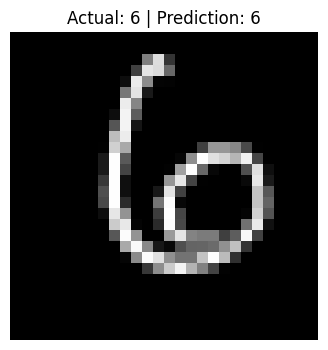

Test Accuracy: 97.00%


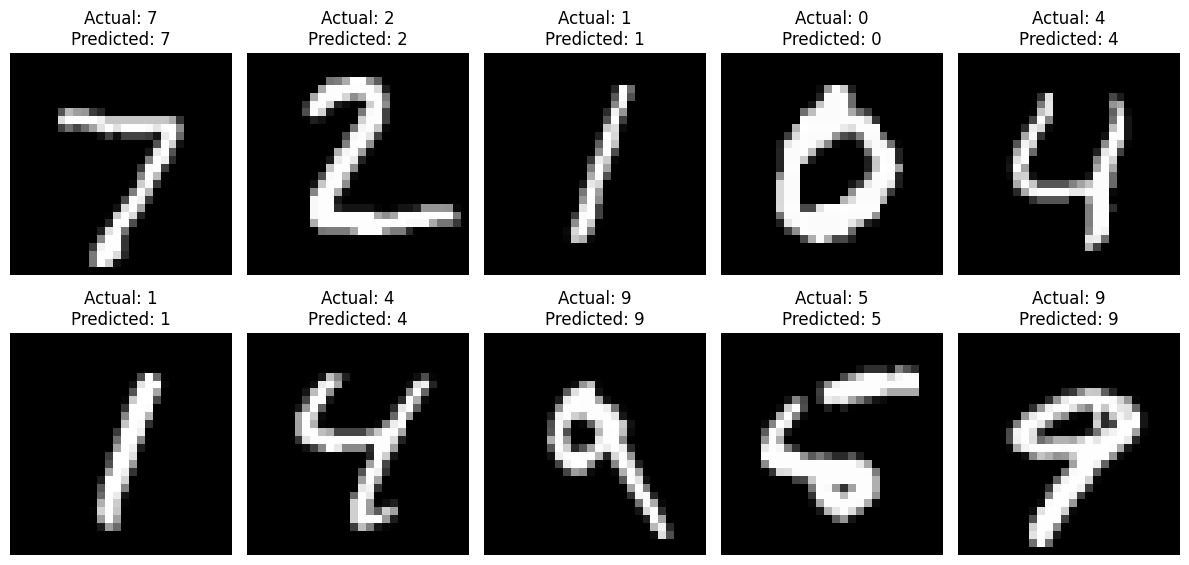

In [1]:
# ==========================================
# Exp-1: Three-Layer Neural Network from Scratch
# ==========================================

# Step 1: Import Necessary Libraries

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from sklearn.preprocessing import OneHotEncoder


# Step 2: Load and Preprocess the Dataset

(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Reshape images from 28x28 to 784 pixels
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

# One-hot encode the labels
encoder = OneHotEncoder(sparse_output=False)

y_train = encoder.fit_transform(y_train.reshape(-1, 1))
y_test = encoder.transform(y_test.reshape(-1, 1))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)


# Step 3: Initialize the Neural Network

input_size = 784
hidden_size = 64
output_size = 10

np.random.seed(42)

# Weights and biases for input-to-hidden layer
W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

# Weights and biases for hidden-to-output layer
W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)


# Step 4: Define Activation and Loss Functions

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    return x * (1 - x)


def loss_function(y, y_hat):
    return -np.mean(
        y * np.log(y_hat + 1e-8) +
        (1 - y) * np.log(1 - y_hat + 1e-8)
    )


# Step 5: Train the Neural Network

epochs = 10
learning_rate = 0.1

losses = []

for epoch in range(epochs):

    total_loss = 0

    for i in range(X_train.shape[0]):

        x = X_train[i:i+1]
        y = y_train[i:i+1]

        # Forward propagation
        z1 = x @ W1 + b1
        a1 = sigmoid(z1)

        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        # Calculate loss
        loss = loss_function(y, a2)
        total_loss += loss

        # Backpropagation
        dz2 = a2 - y

        dW2 = a1.T @ dz2
        db2 = dz2

        dz1 = (dz2 @ W2.T) * sigmoid_derivative(a1)

        dW1 = x.T @ dz1
        db1 = dz1

        # Update weights and biases
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

    epoch_loss = total_loss / X_train.shape[0]
    losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {epoch_loss:.4f}"
    )


# Step 6: Visualize Training Loss

plt.figure(figsize=(8, 5))

plt.plot(losses, marker='o')

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.show()


# Step 7: Define Prediction Function

def predict(img):

    img = img.reshape(1, 784)

    # Forward propagation
    z1 = img @ W1 + b1
    a1 = sigmoid(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    return np.argmax(a2)


# Step 8: Predict a Sample Digit

idx = 100

prediction = predict(X_test[idx])
actual = np.argmax(y_test[idx])

plt.figure(figsize=(4, 4))

plt.imshow(
    X_test[idx].reshape(28, 28),
    cmap='gray'
)

plt.title(
    f"Actual: {actual} | Prediction: {prediction}"
)

plt.axis('off')
plt.show()


# Step 9: Calculate Test Accuracy

correct = 0
test_samples = 1000

for i in range(test_samples):

    prediction = predict(X_test[i])
    actual = np.argmax(y_test[i])

    if prediction == actual:
        correct += 1

accuracy = (correct / test_samples) * 100

print(f"Test Accuracy: {accuracy:.2f}%")


# Step 10: Display Multiple Predictions

plt.figure(figsize=(12, 6))

for i in range(10):

    prediction = predict(X_test[i])
    actual = np.argmax(y_test[i])

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap='gray'
    )

    plt.title(
        f"Actual: {actual}\nPredicted: {prediction}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()